# Video game sales: does genre help predict a title's success?

**Working question:** To what extent does genre help predict whether a game **title** achieves at least one million recorded worldwide sales across all platforms in this dataset? Does publisher improve the prediction?

**Data source:** [Video Games Sales Dataset, Kaggle](https://www.kaggle.com/datasets/sidtwr/videogames-sales-dataset). Keep `Video_Games_Sales_as_at_22_Dec_2016.csv` beside this notebook. The raw file contains one row per game-platform record. We first inspect those rows, then aggregate them by title for the main question.

**Run instructions:** Open this notebook in Jupyter with the CSV beside it and run cells from top to bottom. This is an exploration in progress; model comparison and final report decisions will follow. Keep the original CSV unchanged.

## 1. Load the data

The file uses Latin-1 text encoding. Keep the original CSV unchanged so the analysis can be reproduced.

In [5]:
import pandas as pd
from pathlib import Path

DATA_FILE = Path("Video_Games_Sales_as_at_22_Dec_2016.csv")
df = pd.read_csv(DATA_FILE, encoding="latin1")
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
df.head()

Rows: 16,719; columns: 16


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


## 2. What is in the dataset?

Each row is a game-platform record. Look at the column names and types before making a prediction question.

In [6]:
print(df.dtypes.to_string())
print("\nMissing values by column:")
print(df.isna().sum().sort_values(ascending=False).to_string())

Name                object
Platform            object
Year_of_Release    float64
Genre               object
Publisher           object
NA_Sales           float64
EU_Sales           float64
JP_Sales           float64
Other_Sales        float64
Global_Sales       float64
Critic_Score       float64
Critic_Count       float64
User_Score         float64
User_Count         float64
Developer           object
Rating              object

Missing values by column:
User_Score         9129
User_Count         9129
Critic_Score       8582
Critic_Count       8582
Rating             6769
Developer          6623
Year_of_Release     269
Publisher            54
Name                  2
Genre                 2
NA_Sales              0
Platform              0
JP_Sales              0
EU_Sales              0
Other_Sales           0
Global_Sales          0


## 3. Explore the possible target

`Global_Sales` is measured in millions of copies. Check its spread and how common a one-million-copy game is.

In [7]:
print(df["Global_Sales"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).to_string())
print("\nGames selling at least 1 million:", (df["Global_Sales"] >= 1).sum())
print("Share:", round((df["Global_Sales"] >= 1).mean(), 3))

count    16719.000000
mean         0.533543
std          1.547935
min          0.010000
50%          0.170000
75%          0.470000
90%          1.200000
95%          2.040000
99%          5.458200
max         82.530000

Games selling at least 1 million: 2076
Share: 0.124


## Questions the exploration must answer

- Is one million copies a useful threshold, given the spread of sales?
- Do genre groups differ in both size and share reaching that threshold?
- Does publisher change the apparent genre pattern?
- How often does the same game appear on multiple platforms, and what changes when we combine platform sales?
- Which features would be available when making a prediction? Regional sales already reveal worldwide sales, so they cannot be predictors.

Notes for Project

Started with 2016 Dataset, looked at '2026 Steam estimated steam owners' and compared research questions.
Come to conclusion to ask "Does a video games genre have an impact on sales, more 



## 4. Preliminary comparison using platform records

**Purpose:** Inspect the raw data before deciding the unit of analysis. The graphs below use one row per game-platform record and are **not the final title-level result**. Their differences help show why aggregating platforms matters. We remove the two records with no title or genre for this comparison; the original data remains unchanged.

Overall success rate: 12.4 %


,records,million_sellers,median_sales_millions,success_pct
Genre,,,,
Platform,888,194,0.27,21.8
Shooter,1323,256,0.23,19.3
Fighting,849,125,0.20,14.7
Racing,1249,182,0.19,14.6
Role-Playing,1500,203,0.18,13.5
Sports,2348,305,0.22,13.0
Action,3370,421,0.19,12.5
Simulation,874,93,0.15,10.6
Misc,1750,169,0.16,9.7


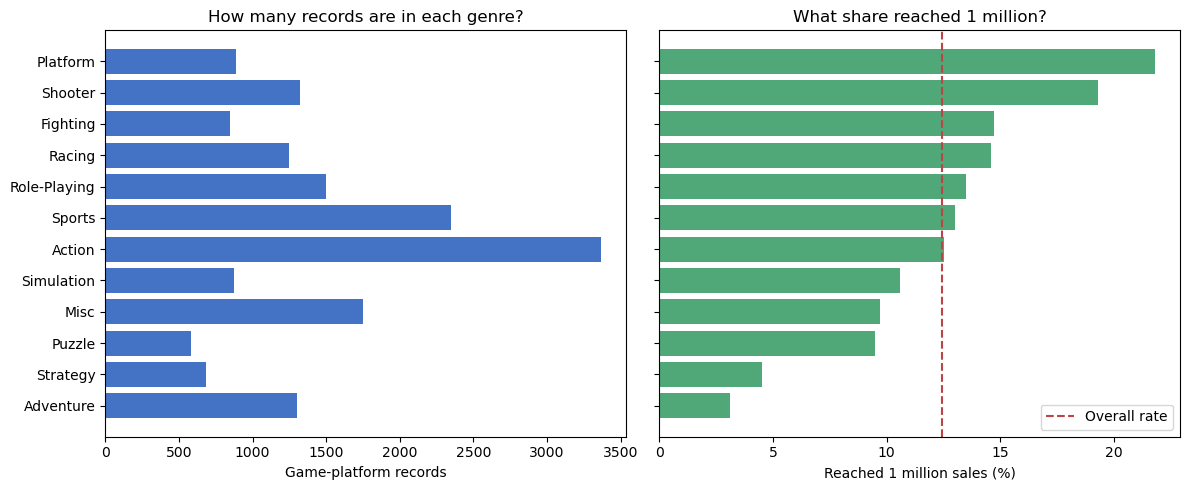

In [8]:
import matplotlib.pyplot as plt

eda = df.dropna(subset=["Name", "Genre"]).copy()
eda["million_seller"] = eda["Global_Sales"] >= 1

genre_summary = eda.groupby("Genre").agg(
    records=("Name", "size"),
    million_sellers=("million_seller", "sum"),
    median_sales_millions=("Global_Sales", "median"),
)
genre_summary["success_pct"] = (100 * genre_summary["million_sellers"] / genre_summary["records"]).round(1)
genre_summary = genre_summary.sort_values("success_pct", ascending=False)
print("Overall success rate:", round(100 * eda["million_seller"].mean(), 1), "%")
display(genre_summary)

plot_data = genre_summary.sort_values("success_pct")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(plot_data.index, plot_data["records"], color="#4472C4")
axes[0].set(xlabel="Game-platform records", title="How many records are in each genre?")
axes[1].barh(plot_data.index, plot_data["success_pct"], color="#50A878")
axes[1].axvline(100 * eda["million_seller"].mean(), color="#BB4444", linestyle="--", label="Overall rate")
axes[1].set(xlabel="Reached 1 million sales (%)", title="What share reached 1 million?")
axes[1].legend()
fig.tight_layout()
plt.show()

**Reading this figure:** The left panel gives the size of each group; the right panel gives its percentage reaching the threshold. A high percentage alone does not show that genre caused success. In this snapshot, Shooter has 256 of 1,323 records (19.3%) reaching one million; Puzzle has 55 of 580 (9.5%); Adventure has 41 of 1,303 (3.1%). “Platform” in the genre table is a *type of game*, whereas the separate `Platform` column names the console or PC.

**Your interpretation:** Which comparison surprised you? What other explanation, besides genre, might produce it? Add your own notes here before making a final claim.

## 5. Does publisher change the genre pattern?

**Purpose:** Test the specific ideas about Nintendo's Puzzle games and Activision's Shooter games. These groups are examples for exploration, not evidence that a publisher causes sales. Counts matter because the groups are different sizes.

,genre,publisher_group,records,million_sellers,success_pct
0,Puzzle,Nintendo,74,28,37.8
1,Puzzle,Other publishers,506,27,5.3
2,Shooter,Activision,162,59,36.4
3,Shooter,Other publishers,1161,197,17.0


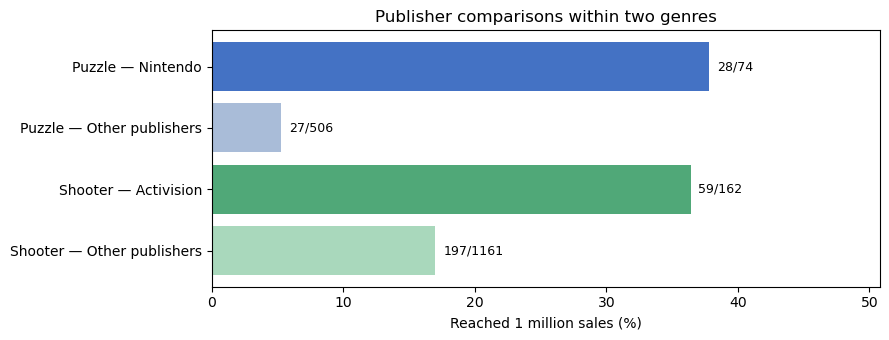

In [9]:
publisher_checks = []
for genre, publisher in [("Puzzle", "Nintendo"), ("Shooter", "Activision")]:
    subset = eda.loc[eda["Genre"] == genre].copy()
    subset["publisher_group"] = subset["Publisher"].eq(publisher).map({True: publisher, False: "Other publishers"})
    summary = subset.groupby("publisher_group")["million_seller"].agg(records="size", million_sellers="sum")
    summary["success_pct"] = (100 * summary["million_sellers"] / summary["records"]).round(1)
    summary.insert(0, "genre", genre)
    publisher_checks.append(summary.reset_index())
publisher_summary = pd.concat(publisher_checks, ignore_index=True)
publisher_summary = publisher_summary[["genre", "publisher_group", "records", "million_sellers", "success_pct"]]
display(publisher_summary)

labels = publisher_summary["genre"] + " — " + publisher_summary["publisher_group"]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(labels.iloc[::-1], publisher_summary["success_pct"].iloc[::-1], color=["#4472C4", "#A9BCD8", "#50A878", "#A9D8BC"][::-1])
ax.set(xlabel="Reached 1 million sales (%)", title="Publisher comparisons within two genres")
for i, row in enumerate(publisher_summary.iloc[::-1].itertuples()):
    ax.text(row.success_pct + 0.6, i, f"{row.million_sellers}/{row.records}", va="center", fontsize=9)
ax.set_xlim(0, publisher_summary["success_pct"].max() + 13)
fig.tight_layout()
plt.show()

**Reading this figure:** Nintendo's Puzzle records reach the threshold more often than Puzzle records from other publishers. Activision's Shooter records also have a higher rate than other Shooter records, but many Shooters from other publishers reach the threshold. Publisher, series and console may be intertwined, so these are descriptive comparisons.

**Your interpretation:** Which of your original ideas is supported? Which needs changing? What would you check next to see whether publisher itself explains the difference?

## 6. Check repeated games before splitting data

**Purpose:** The same title may have separate sales rows for different platforms. A later train/test split must keep those versions together, otherwise a model could see one version while being tested on another.

In [10]:
platforms_per_title = eda.groupby("Name")["Platform"].nunique()
print(f"Unique titles: {len(platforms_per_title):,}")
print(f"Titles appearing on more than one platform: {(platforms_per_title > 1).sum():,}")
print("Example versions of one title:")
display(eda.loc[eda["Name"] == "Grand Theft Auto V", ["Name", "Platform", "Year_of_Release", "Genre", "Publisher", "Global_Sales"]])

Unique titles: 11,562
Titles appearing on more than one platform: 2,806
Example versions of one title:


,Name,Platform,Year_of_Release,Genre,Publisher,Global_Sales
16,Grand Theft Auto V,PS3,2013.0,Action,Take-Two Interactive,21.04
23,Grand Theft Auto V,X360,2013.0,Action,Take-Two Interactive,16.27
42,Grand Theft Auto V,PS4,2014.0,Action,Take-Two Interactive,12.61
165,Grand Theft Auto V,XOne,2014.0,Action,Take-Two Interactive,5.48
1730,Grand Theft Auto V,PC,2015.0,Action,Take-Two Interactive,1.17


## Decisions from the preliminary exploration

1. A title can appear on multiple platforms, so a one-million threshold on a single platform may misclassify a successful game. **We will sum recorded platform sales by title for the main analysis.**
2. Genre should be tested against a baseline, then alongside publisher. We will choose models after interpreting the title-level plots.
3. The main model will not use regional sales: they are components of `Global_Sales`. We will not use critic or user scores in the main comparison because many are missing and they arise after release.
4. A raw row is a platform release, not a distinct game title. The title-level grouping and its ambiguities must be documented.

**Student notes:** Record your own interpretation and any alternative explanation here.

## 7. Real-world motivation: Resident Evil's changing direction

This is **context for the research question**, not a result of the 2016 dataset or proof that genre causes sales.

- Capcom's [history of the series](https://www.capcom.co.jp/ir/english/feature/hit2013.html) says sales had been declining before *Resident Evil 4*, prompting a major redesign. Its [2013 annual report](https://www.capcom.co.jp/ir/english/data/pdf/annual/2013/annual_2013_01.pdf) describes *Resident Evil 5* as the series' highest seller at that point and says feedback from its buyers helped shape *Resident Evil 6*.
- Capcom's [2014 annual report](https://www.capcom.co.jp/ir/english/data/pdf/annual/2014/annual_2014_01.pdf) says *Resident Evil 6* sold about five million at the reporting point, below an original ambition of over seven million. This is a missed company target, not evidence that nobody bought the game.
- In a [2016 interview with producer Masachika Kawata](https://gameinformer.com/b/features/archive/2016/12/27/producer-masachika-kawata-spills-his-guts-about-resident-evil-7), Capcom said fan requests for a return to survival horror were a major factor in *Resident Evil 7*'s horror focus. Its [2016 announcement](https://www.capcom.co.jp/ir/english/news/pdf/e160614b.pdf) also describes the shift in design. Capcom later reported [more than ten million cumulative shipments](https://www.capcom.co.jp/ir/english/news/html/e211011.html) for *Resident Evil 7*.

**Careful conclusion:** A company may weigh sales, fan response and creative direction when choosing a game's design. These sources do not show that Capcom selected each genre solely by comparing genre-wide sales, or that the horror direction alone caused *Resident Evil 7*'s later sales. The 2016 file contains *Resident Evil 4–6*, but *Resident Evil 7* came out in 2017 and is absent. The file's broad labels (Action and Shooter) do not identify survival horror as a separate genre. Keep the case study in the introduction or reflection, while the model tests a broader question across titles in the dataset.

**Student judgment:** Which factor in this story seems most plausible to you, and what evidence would be needed to separate its effect from the others?

In [11]:
resident_evil = eda.loc[eda["Name"].isin(["Resident Evil 4", "Resident Evil 5", "Resident Evil 6", "Resident Evil 7"]),
    ["Name", "Platform", "Year_of_Release", "Genre", "Publisher", "Global_Sales"]]
print("Resident Evil 7 rows in this file:", (eda["Name"] == "Resident Evil 7").sum())
display(resident_evil.sort_values(["Name", "Platform"]))

Resident Evil 7 rows in this file: 0


,Name,Platform,Year_of_Release,Genre,Publisher,Global_Sales
1068,Resident Evil 4,GC,2005.0,Action,Capcom,1.69
14658,Resident Evil 4,PC,2007.0,Action,Ubisoft,0.03
350,Resident Evil 4,PS2,2005.0,Action,Capcom,3.62
732,Resident Evil 4,Wii,2007.0,Action,Capcom,2.22
12200,Resident Evil 5,PC,2009.0,Action,Capcom,0.07
199,Resident Evil 5,PS3,2009.0,Action,Capcom,5.09
375,Resident Evil 5,X360,2009.0,Action,Capcom,3.50
13676,Resident Evil 6,PC,2012.0,Shooter,Capcom,0.04
449,Resident Evil 6,PS3,2012.0,Shooter,Capcom,3.10
11584,Resident Evil 6,PS4,2016.0,Shooter,Capcom,0.08


## 8. The one-million threshold: platform versus title

Capcom [calls more than one million units a major hit for a **title**](https://www.capcom.co.jp/ir/english/business/million.html). The following table is a diagnostic for the *raw platform rows* only. It shows why we chose to combine platforms: the same business threshold means something different when applied to just one version of a game. The title-level threshold check appears below.

In [12]:
thresholds = [0.5, 1, 2, 5]
threshold_check = pd.DataFrame({
    "threshold_million_copies": thresholds,
    "records_reaching_threshold": [(eda["Global_Sales"] >= t).sum() for t in thresholds],
    "share_of_records_pct": [round(100 * (eda["Global_Sales"] >= t).mean(), 1) for t in thresholds],
})
display(threshold_check)

,threshold_million_copies,records_reaching_threshold,share_of_records_pct
0,0.5,4005,24.0
1,1.0,2075,12.4
2,2.0,855,5.1
3,5.0,208,1.2


**Decision:** Use one million **combined recorded sales across platforms** as the working title-level success threshold. This matches the publisher decision more closely than one million for a single platform. We still need to test whether the result is sensitive to the threshold and to ambiguous title names.

## 9. Make one record per game title

**Why:** A title released on several consoles should have its recorded worldwide sales added across those platforms. This file has no Steam-specific platform: `PC` is its computer category, and Nintendo Switch is outside its 2016 coverage. We do not assume any platform is the largest without data.

**Quality checks:** Exact title matching can accidentally combine different games or duplicate a platform's sales. We conservatively remove titles with conflicting genre labels or repeated title-platform pairs. This removes eight title names; the names and counts are printed below. Some same-name releases many years apart can still be ambiguous, so we flag those for a sensitivity check.

A second check found a clear genre error: all rows for *FIFA Soccer 13* are labelled `Action`, while [EA identifies it as an EA SPORTS football game](https://news.ea.com/press-releases/press-releases-details/2012/EA-SPORTS-FIFA-Soccer-13-Sells-over-4.5-Million-Games-in-Five-Days-to-Become-Biggest-Videogame-Launch-of-2012/default.aspx). We change this title to `Sports` **in the cleaned copy only**. The raw file and preliminary plots remain unchanged. Other genre errors may remain.

In [13]:
genre_counts_per_title = eda.groupby("Name")["Genre"].nunique()
conflicting_genre_names = set(genre_counts_per_title[genre_counts_per_title > 1].index)
repeated_platform_names = set(eda.loc[eda.duplicated(["Name", "Platform"], keep=False), "Name"])
ambiguous_names = conflicting_genre_names | repeated_platform_names
print("Titles with conflicting genre labels:", len(conflicting_genre_names))
print("Titles with repeated name-platform pairs:", len(repeated_platform_names))
print("Distinct titles excluded:", len(ambiguous_names))
print("Excluded title names:", ", ".join(sorted(ambiguous_names)))
title_records = eda.loc[~eda["Name"].isin(ambiguous_names)].copy()
# Verified correction in the cleaned copy: EA SPORTS FIFA Soccer 13 is a sports game.
title_records.loc[title_records["Name"] == "FIFA Soccer 13", "Genre"] = "Sports"
print("FIFA Soccer 13 genre after documented correction:", title_records.loc[title_records["Name"] == "FIFA Soccer 13", "Genre"].unique().tolist())

Titles with conflicting genre labels: 5
Titles with repeated name-platform pairs: 3
Distinct titles excluded: 8
Excluded title names: Battlezone, Culdcept, Little Busters! Converted Edition, Madden NFL 13, Need for Speed: Most Wanted, Sonic the Hedgehog, Steins;Gate: Hiyoku Renri no Darling, Syndicate
FIFA Soccer 13 genre after documented correction: ['Sports']


In [14]:
def known_publishers(values):
    return tuple(sorted(set(values.dropna())))

title_groups = title_records.groupby("Name", sort=True)
title_data = title_groups.agg(
    Genre=("Genre", "first"),
    total_sales_millions=("Global_Sales", "sum"),
    platform_count=("Platform", "nunique"),
    first_release_year=("Year_of_Release", "min"),
    last_release_year=("Year_of_Release", "max"),
    publishers=("Publisher", known_publishers),
)
title_data["release_year_span"] = title_data["last_release_year"] - title_data["first_release_year"]
title_data["million_seller"] = title_data["total_sales_millions"] >= 1
print(f"Titles analysed: {len(title_data):,}")
print(f"Titles reaching 1 million combined recorded sales: {title_data['million_seller'].sum():,}")
print(f"Share reaching 1 million: {100 * title_data['million_seller'].mean():.1f}%")
print(f"Titles whose recorded release years span more than 8 years: {(title_data['release_year_span'] > 8).sum():,}")
display(title_data.loc[["Resident Evil 4", "Resident Evil 5", "Resident Evil 6"],
    ["Genre", "total_sales_millions", "platform_count", "publishers"]])

Titles analysed: 11,554
Titles reaching 1 million combined recorded sales: 2,042
Share reaching 1 million: 17.7%
Titles whose recorded release years span more than 8 years: 82


,Genre,total_sales_millions,platform_count,publishers
Name,,,,
Resident Evil 4,Action,7.56,4,"(Capcom, Ubisoft)"
Resident Evil 5,Action,8.66,3,"(Capcom,)"
Resident Evil 6,Shooter,5.22,5,"(Capcom,)"


**Interpretation:** Sales are summed only across the platform rows present in this file. That is a dataset total, not a verified lifetime sales total; missing platforms or later digital sales could make it incomplete. Some title names are reused, and later ports can be released years after the first version. We will test whether excluding unusually long release spans changes the broad result.

## 10. Compare title-level success by genre

**Purpose:** The table and chart below answer the first research question using one row per title. Counts are shown beside success rates. The dashed line is the overall title success rate, which gives a simple descriptive reference. The first table checks whether one million gives enough successful examples for modelling.

In [15]:
title_thresholds = [0.5, 1, 2, 5]
title_threshold_check = pd.DataFrame({
    "threshold_million_copies": title_thresholds,
    "titles_reaching_threshold": [(title_data["total_sales_millions"] >= t).sum() for t in title_thresholds],
    "share_of_titles_pct": [round(100 * (title_data["total_sales_millions"] >= t).mean(), 1) for t in title_thresholds],
})
display(title_threshold_check)

,threshold_million_copies,titles_reaching_threshold,share_of_titles_pct
0,0.5,3318,28.7
1,1.0,2042,17.7
2,2.0,1012,8.8
3,5.0,318,2.8


,titles,successful_titles,median_sales_millions,success_pct
Genre,,,,
Platform,587,185,0.42,31.5
Shooter,823,224,0.27,27.2
Racing,771,190,0.28,24.6
Sports,1379,311,0.29,22.6
Action,1954,411,0.22,21.0
Fighting,613,122,0.24,19.9
Role-Playing,1227,195,0.20,15.9
Simulation,730,95,0.16,13.0
Misc,1329,166,0.17,12.5


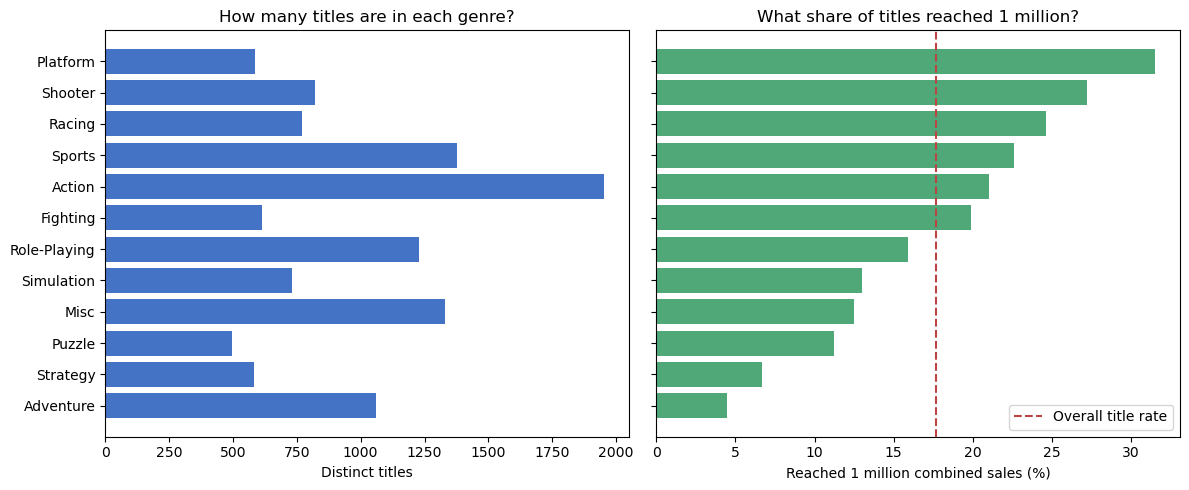

In [16]:
title_genre_summary = title_data.groupby("Genre").agg(
    titles=("million_seller", "size"),
    successful_titles=("million_seller", "sum"),
    median_sales_millions=("total_sales_millions", "median"),
)
title_genre_summary["success_pct"] = (100 * title_genre_summary["successful_titles"] / title_genre_summary["titles"]).round(1)
title_genre_summary = title_genre_summary.sort_values("success_pct", ascending=False)
display(title_genre_summary)

plot_titles = title_genre_summary.sort_values("success_pct")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(plot_titles.index, plot_titles["titles"], color="#4472C4")
axes[0].set(xlabel="Distinct titles", title="How many titles are in each genre?")
axes[1].barh(plot_titles.index, plot_titles["success_pct"], color="#50A878")
axes[1].axvline(100 * title_data["million_seller"].mean(), color="#BB4444", linestyle="--", label="Overall title rate")
axes[1].set(xlabel="Reached 1 million combined sales (%)", title="What share of titles reached 1 million?")
axes[1].legend()
fig.tight_layout()
plt.show()

**Reading this figure:** These are the **main title-level rates**. Compare them with the earlier platform-level figures: the unit of analysis changes the percentages. This is an association; it does not show that genre causes a title to sell well. A genre such as “Platform” is a game category, not the hardware column.

**Student judgment:** Which genre difference seems commercially meaningful? Could publisher, series reputation or release era explain part of it? Write your interpretation before we choose a model.

## 11. Check publisher patterns at title level

**Purpose:** Revisit Nintendo's Puzzle titles and Activision's Shooter titles after combining platforms. Here “Nintendo” and “Activision” mean the company appears in the title's publisher list in this file; some titles have more than one recorded publisher. These groups are descriptive examples, not causal tests.

,publisher_group,genre,titles,successful_titles,success_pct
0,Nintendo,Puzzle,67,26,38.8
1,Other publishers,Puzzle,431,30,7.0
2,Activision,Shooter,69,35,50.7
3,Other publishers,Shooter,754,189,25.1


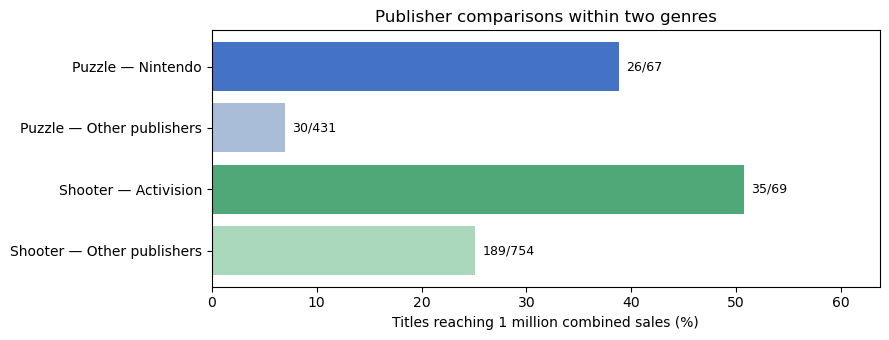

In [17]:
title_publisher_checks = []
for genre, publisher in [("Puzzle", "Nintendo"), ("Shooter", "Activision")]:
    subset = title_data.loc[title_data["Genre"] == genre].copy()
    subset["publisher_group"] = subset["publishers"].apply(lambda names: publisher if publisher in names else "Other publishers")
    summary = subset.groupby("publisher_group")["million_seller"].agg(titles="size", successful_titles="sum")
    summary["success_pct"] = (100 * summary["successful_titles"] / summary["titles"]).round(1)
    summary.insert(0, "genre", genre)
    title_publisher_checks.append(summary.reset_index())
title_publisher_summary = pd.concat(title_publisher_checks, ignore_index=True)
display(title_publisher_summary)

labels = title_publisher_summary["genre"] + " — " + title_publisher_summary["publisher_group"]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(labels.iloc[::-1], title_publisher_summary["success_pct"].iloc[::-1],
    color=["#4472C4", "#A9BCD8", "#50A878", "#A9D8BC"][::-1])
ax.set(xlabel="Titles reaching 1 million combined sales (%)", title="Publisher comparisons within two genres")
for i, row in enumerate(title_publisher_summary.iloc[::-1].itertuples()):
    ax.text(row.success_pct + 0.7, i, f"{row.successful_titles}/{row.titles}", va="center", fontsize=9)
ax.set_xlim(0, title_publisher_summary["success_pct"].max() + 13)
fig.tight_layout()
plt.show()

**Working interpretation:** Title-level publisher patterns can differ from platform-level ones. Even if Nintendo's Puzzle titles have a higher success rate, they may also be established series, have different marketing budgets or target different audiences. Those explanations are not measured here.

**Next methodological check:** Exclude titles whose release years span more than eight years and see whether genre rates change substantially. A long span can indicate a re-release or a reused name, but it is not proof of an error. The main comparison keeps them until we assess the impact.

In [18]:
short_span_titles = title_data.loc[title_data["release_year_span"].isna() | (title_data["release_year_span"] <= 8)]
span_sensitivity = pd.DataFrame({
    "sample": ["All eligible titles", "Exclude year span over 8 years"],
    "titles": [len(title_data), len(short_span_titles)],
    "one_million_rate_pct": [round(100 * title_data["million_seller"].mean(), 1),
                             round(100 * short_span_titles["million_seller"].mean(), 1)],
})
display(span_sensitivity)

,sample,titles,one_million_rate_pct
0,All eligible titles,11554,17.7
1,Exclude year span over 8 years,11472,17.3


## 12. Evidence for combining platforms

**Purpose:** Count titles that would be labelled unsuccessful if we required *one platform* to reach one million, even though their combined recorded sales reach the threshold. This directly tests the concern that a game can sell across several platforms without any single version passing the line.

In [19]:
per_title_platform_sales = title_records.groupby("Name")["Global_Sales"].agg(combined_sales="sum", best_single_platform="max", platform_rows="size")
split_success = per_title_platform_sales.loc[
    (per_title_platform_sales["combined_sales"] >= 1) &
    (per_title_platform_sales["best_single_platform"] < 1)
]
print("Titles reaching 1 million combined sales but no individual platform reaches 1 million:", len(split_success))
print("Share of all title-level million-sellers:", round(100 * len(split_success) / title_data["million_seller"].sum(), 1), "%")
print("Example: LEGO Jurassic World")
display(title_records.loc[title_records["Name"] == "LEGO Jurassic World",
    ["Name", "Platform", "Global_Sales"]].sort_values("Global_Sales", ascending=False))
print("Combined recorded sales:", round(title_data.loc["LEGO Jurassic World", "total_sales_millions"], 2), "million")

Titles reaching 1 million combined sales but no individual platform reaches 1 million: 426
Share of all title-level million-sellers: 20.9 %
Example: LEGO Jurassic World


,Name,Platform,Global_Sales
2301,LEGO Jurassic World,PS4,0.90
2402,LEGO Jurassic World,X360,0.87
2435,LEGO Jurassic World,PS3,0.85
3084,LEGO Jurassic World,XOne,0.65
3230,LEGO Jurassic World,3DS,0.62
3840,LEGO Jurassic World,WiiU,0.52
7125,LEGO Jurassic World,PSV,0.22
13942,LEGO Jurassic World,PC,0.04


Combined recorded sales: 4.67 million


**Interpretation:** This is evidence that the chosen unit of analysis changes which titles count as successful. `LEGO Jurassic World` has no platform row at one million, yet its listed platform rows total 4.67 million. This justifies using the title-level target for a question about whether a **game title** succeeds. It does not prove the dataset captures every platform or every sale.

## 13. What the platform codes mean

`Platform` is the **hardware or computer system on which that version was released**. For example, `PS4` means PlayStation 4 and `XOne` means Xbox One. It is different from the `Platform` **genre**, which means a platform-style game such as *Super Mario Bros.* One title can have several hardware rows, which we combined above.

| Family | Codes in this file |
| --- | --- |
| PlayStation | `PS` original PlayStation; `PS2`, `PS3`, `PS4`; `PSP` PlayStation Portable; `PSV` PlayStation Vita |
| Xbox | `XB` original Xbox; `X360` Xbox 360; `XOne` Xbox One |
| Nintendo | `NES`, `SNES`, `N64`, `GC` GameCube, `Wii`, `WiiU`; `GB` Game Boy, `GBA` Game Boy Advance, `DS`, `3DS` |
| Sega | `GEN` Genesis/Mega Drive; `SCD` Sega CD; `SAT` Saturn; `DC` Dreamcast; `GG` Game Gear |
| Other | `PC` computer; `2600` Atari 2600; `NG` Neo Geo; `WS` WonderSwan; `3DO`; `TG16` TurboGrafx-16; `PCFX` PC-FX |

Nintendo Switch, PlayStation 5 and Xbox Series consoles do not appear because this is a 2016 snapshot. `PC` is **not a measure of Steam sales specifically**.

## 14. Did the mix of genres change by release year?

**Purpose:** Check the student's hypothesis that a hit in one period might be followed by more titles of the same genre. We count **distinct title names by their earliest recorded release year**, then compare Action and Shooter counts and shares. We focus on 2005–2015: 2016 is close to the December 2016 snapshot and has less time for releases and sales to appear; a few later release years are inconsistent with the snapshot and are excluded. These are counts of **titles recorded in this sales file**, not all games released in the market.

,all_titles,Action_titles,Shooter_titles,Action_share_pct,Shooter_share_pct
release_year,,,,,
2010,857,117,45,13.7,5.3
2011,742,121,53,16.3,7.1
2012,402,171,21,42.5,5.2
2013,292,66,24,22.6,8.2
2014,278,76,13,27.3,4.7
2015,323,136,13,42.1,4.0


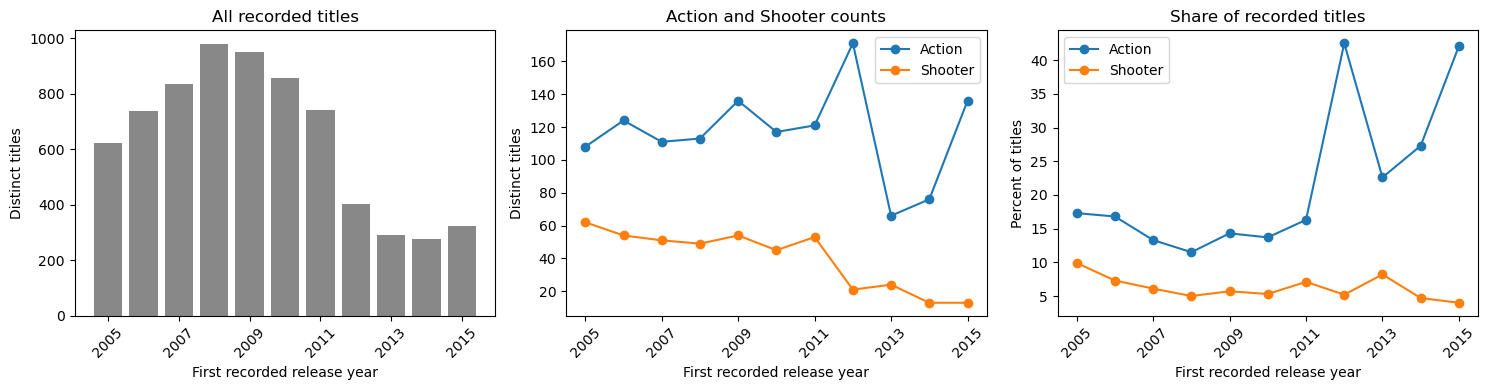

In [20]:
trend_titles = title_data.loc[title_data["first_release_year"].between(2005, 2015)].copy()
trend_titles["release_year"] = trend_titles["first_release_year"].astype(int)
yearly_total = trend_titles.groupby("release_year").size().rename("all_titles")
yearly_genres = pd.crosstab(trend_titles["release_year"], trend_titles["Genre"])
yearly_trend = pd.DataFrame({
    "all_titles": yearly_total,
    "Action_titles": yearly_genres["Action"],
    "Shooter_titles": yearly_genres["Shooter"],
})
yearly_trend["Action_share_pct"] = (100 * yearly_trend["Action_titles"] / yearly_trend["all_titles"]).round(1)
yearly_trend["Shooter_share_pct"] = (100 * yearly_trend["Shooter_titles"] / yearly_trend["all_titles"]).round(1)
display(yearly_trend.loc[2010:2015])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(yearly_trend.index, yearly_trend["all_titles"], color="#888888")
axes[0].set(title="All recorded titles", ylabel="Distinct titles", xlabel="First recorded release year")
axes[1].plot(yearly_trend.index, yearly_trend["Action_titles"], marker="o", label="Action")
axes[1].plot(yearly_trend.index, yearly_trend["Shooter_titles"], marker="o", label="Shooter")
axes[1].set(title="Action and Shooter counts", ylabel="Distinct titles", xlabel="First recorded release year")
axes[1].legend()
axes[2].plot(yearly_trend.index, yearly_trend["Action_share_pct"], marker="o", label="Action")
axes[2].plot(yearly_trend.index, yearly_trend["Shooter_share_pct"], marker="o", label="Shooter")
axes[2].set(title="Share of recorded titles", ylabel="Percent of titles", xlabel="First recorded release year")
axes[2].legend()
for ax in axes:
    ax.set_xticks([2005, 2007, 2009, 2011, 2013, 2015])
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

**Reading this figure:** The 2014 Action share is higher than 2013, but the total number of recorded titles changes sharply too. Looking at a share avoids confusing a shift in the dataset's overall size with a shift in genre mix. The chart does **not** establish that publishers reacted to a particular hit: `Global_Sales` is cumulative at the dataset snapshot, with no annual sales history or game-development start dates. Also, title coverage, platform generations and genre labelling may change across years.

**Student judgment:** Which comparison is more convincing for your idea: the number of Action titles or Action's share of all recorded titles? Why? What extra data would you need to show that studios responded to a previous hit?

## 15. Is the Shooter pattern driven by Call of Duty?

**Purpose:** The student suggested that *Call of Duty* may dominate Shooter sales. We check both its **share of Shooter titles** and its **share of recorded Shooter sales**. A franchise can contribute many sales without representing most games in its genre. This is based on names beginning `Call of Duty`; some spin-offs or differently named titles might be missed.

In [21]:
shooter_titles = title_data.loc[title_data["Genre"] == "Shooter"].copy()
call_of_duty = shooter_titles.index.str.startswith("Call of Duty")
cod_comparison = pd.DataFrame({
    "group": ["Call of Duty Shooter titles", "Other Shooter titles"],
    "titles": [call_of_duty.sum(), (~call_of_duty).sum()],
    "combined_recorded_sales_millions": [shooter_titles.loc[call_of_duty, "total_sales_millions"].sum(),
                                         shooter_titles.loc[~call_of_duty, "total_sales_millions"].sum()],
    "titles_reaching_1m": [shooter_titles.loc[call_of_duty, "million_seller"].sum(),
                          shooter_titles.loc[~call_of_duty, "million_seller"].sum()],
})
cod_comparison["success_pct"] = (100 * cod_comparison["titles_reaching_1m"] / cod_comparison["titles"]).round(1)
display(cod_comparison)
print(f"Call of Duty is {100 * call_of_duty.mean():.1f}% of Shooter titles but {100 * shooter_titles.loc[call_of_duty, 'total_sales_millions'].sum() / shooter_titles['total_sales_millions'].sum():.1f}% of their combined recorded sales.")

,group,titles,combined_recorded_sales_millions,titles_reaching_1m,success_pct
0,Call of Duty Shooter titles,20,252.07,16,80.0
1,Other Shooter titles,803,799.90,208,25.9


Call of Duty is 2.4% of Shooter titles but 24.0% of their combined recorded sales.


**Interpretation:** A strong franchise can shape a genre's total sales without explaining the success of every title in it. To test whether the genre result depends on a single franchise, later model evaluation can repeat key comparisons with *Call of Duty* titles removed. That would be a sensitivity check, not the main dataset.

**Limit:** This file records sales accumulated by the 2016 snapshot, not sales achieved in each release year. It cannot show that another studio saw a 2012 hit and began developing a similar game for 2014. A convincing response-to-trend study would require complete yearly release data, sales available at the time, and ideally development or announcement dates.

## 16. Try it yourself: SPSS-style comparisons in Python

In SPSS you might put **Year** in the rows and **Genre** in the columns. In pandas, `pd.crosstab` does the same thing: each table cell counts titles with that combination. We use `title_data`, which has one row per title after combining platforms.

**Your controls:** Change `START_YEAR`, `END_YEAR`, or the names in `GENRES`, then click the first code cell below and press **Shift + Enter**. Run the next cell to refresh the percentages and chart. Genre names must match the table exactly, such as `Action`, `Shooter`, `Puzzle`, or `Sports`. This is a practice view; changing these controls does not alter the original CSV.

In [26]:
START_YEAR = 2010
END_YEAR = 2015
GENRES = ["Sports", "Shooter"]

selected_titles = title_data.loc[title_data["first_release_year"].between(START_YEAR, END_YEAR)].copy()
selected_titles["Year"] = selected_titles["first_release_year"].astype(int)
counts_by_year_and_genre = pd.crosstab(selected_titles["Year"], selected_titles["Genre"])
print("Number of recorded titles:")
display(counts_by_year_and_genre.reindex(columns=GENRES, fill_value=0))

Number of recorded titles:


Genre,Sports,Shooter
Year,,
2010,99,45
2011,60,53
2012,20,21
2013,20,24
2014,20,13
2015,17,13


Percentage of ALL recorded titles in each year:


Genre,Action,Shooter
Year,,
2010,13.7,5.3
2011,16.3,7.1
2012,42.5,5.2
2013,22.6,8.2
2014,27.3,4.7
2015,42.1,4.0


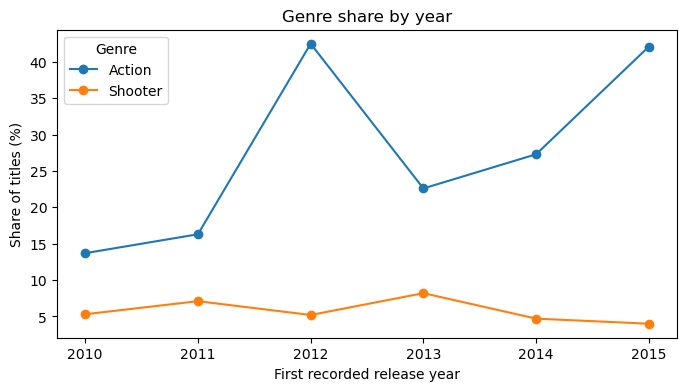

In [23]:
percent_by_year_and_genre = (counts_by_year_and_genre.div(counts_by_year_and_genre.sum(axis=1), axis=0) * 100).round(1)
print("Percentage of ALL recorded titles in each year:")
display(percent_by_year_and_genre.reindex(columns=GENRES, fill_value=0))

ax = percent_by_year_and_genre.reindex(columns=GENRES, fill_value=0).plot(marker="o", figsize=(8, 4))
ax.set(xlabel="First recorded release year", ylabel="Share of titles (%)", title="Genre share by year")
ax.legend(title="Genre")
plt.show()

**How to read it:** The count table answers “How many Action and Shooter titles are recorded for each year?” The percentage table answers “Out of **all** titles recorded that year, what share was Action or Shooter?” Percentages are often fairer when different years contain different total numbers of titles. Try adding `"Puzzle"` to `GENRES` and running the two code cells again. Describe one change you notice, and remember that a change in this dataset does not prove what caused it.